In [1]:
# Notebook 08 — Cell 1
# Load the frozen eligibility policy and create the primary split.
# No preprocessing or model fitting.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Locate the project from the notebook's working directory.
roots = [
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/acoustic_features_recording.csv").is_file()
]
assert len(roots) == 1, "Set PROJECT_ROOT explicitly if detection is ambiguous."
PROJECT_ROOT = roots[0]

eligibility_dir = (
    PROJECT_ROOT / "data/processed/supervised/audit"
    / "eligibility_20261030T011435890786Z"
)
policy_path = eligibility_dir / "eligibility_policy.json"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

expected_policy_hash = (
    "c4793f2e42d7156605bed0d19a85986d586f5c46ee5386a40725616e8b977b61"
)
assert sha256_file(policy_path) == expected_policy_hash, "Policy changed."

policy = json.loads(policy_path.read_text(encoding="utf-8"))
membership = pd.read_csv(
    eligibility_dir / "cohort_membership.csv",
    dtype={"recording_id": "string"},
)

input_paths = {
    "Recording features": "data/processed/acoustic_features_recording.csv",
    "Window features": "data/processed/acoustic_features_window.csv",
    "Recording metadata": "data/processed/master_metadata.csv",
    "Feature manifest": "data/manifests/feature_manifest.csv",
}
for label, relative in input_paths.items():
    assert sha256_file(PROJECT_ROOT / relative) == policy["input_hashes"][label], (
        f"Input changed: {label}"
    )

metadata = pd.read_csv(
    PROJECT_ROOT / input_paths["Recording metadata"],
    dtype={"recording_id": "string"},
)

# Parse saved booleans explicitly.
for column in ["primary_eligible", "sensitivity_eligible"]:
    values = membership[column].astype("string").str.lower()
    assert values.isin(["true", "false"]).all()
    membership[column] = values.eq("true")

split_table = (
    membership.loc[membership["primary_eligible"]]
    .merge(
        metadata[["recording_id", "latitude", "longitude"]],
        on="recording_id",
        how="left",
        validate="one_to_one",
    )
    .sort_values("recording_id")
    .reset_index(drop=True)
)

assert len(split_table) == 236
assert split_table["recording_id"].is_unique
assert split_table["model_state"].isin(["CA", "AZ", "TX"]).all()

coordinates = split_table[["latitude", "longitude"]].apply(
    pd.to_numeric, errors="raise"
)
assert np.isfinite(coordinates.to_numpy()).all()

# Exact numeric coordinate pairs; no arbitrary decimal rounding.
keys = list(map(tuple, coordinates.to_numpy()))
unique_keys = sorted(set(keys))
group_lookup = {
    key: f"LOC_{number:04d}"
    for number, key in enumerate(unique_keys, start=1)
}
split_table["location_group"] = [group_lookup[key] for key in keys]

assert (
    split_table.groupby("location_group")["model_state"].nunique().max() == 1
), "A coordinate group has conflicting corrected states."

splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

# Fold zero is preselected; no searching across folds or random seeds.
development_idx, test_idx = next(splitter.split(
    X=np.zeros((len(split_table), 1)),
    y=split_table["model_state"],
    groups=split_table["location_group"],
))

split_table["partition"] = "development"
split_table.loc[test_idx, "partition"] = "test"

development = split_table.loc[
    split_table["partition"].eq("development")
]
test = split_table.loc[split_table["partition"].eq("test")]

assert set(development["recording_id"]).isdisjoint(test["recording_id"])
assert set(development["location_group"]).isdisjoint(test["location_group"])
assert set(development["model_state"]) == {"CA", "AZ", "TX"}
assert set(test["model_state"]) == {"CA", "AZ", "TX"}

print("RECORDINGS BY PARTITION")
print(pd.crosstab(
    split_table["model_state"], split_table["partition"]
).to_string())

print("\nLOCATION GROUPS BY PARTITION")
print(
    split_table.groupby(["model_state", "partition"])["location_group"]
    .nunique().unstack(fill_value=0).to_string()
)

print("\nSENSITIVITY SUBSET — SAME ASSIGNMENTS")
print(pd.crosstab(
    split_table.loc[split_table["sensitivity_eligible"], "model_state"],
    split_table.loc[split_table["sensitivity_eligible"], "partition"],
).to_string())

print("\nTest fraction:", round(len(test) / len(split_table), 3))
print("Recording overlap: 0")
print("Exact-coordinate group overlap: 0")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
split_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/splits"
    / f"primary_{stamp}"
)
split_dir.mkdir(parents=True, exist_ok=False)

split_table.to_csv(split_dir / "primary_split_manifest.csv", index=False)
(split_dir / "split_protocol.json").write_text(
    json.dumps({
        "method": "StratifiedGroupKFold",
        "n_splits": 5,
        "selected_holdout_fold": 0,
        "random_state": 42,
        "group_definition": "Exact numeric latitude/longitude pair",
        "policy_sha256": expected_policy_hash,
        "membership_sha256": sha256_file(
            eligibility_dir / "cohort_membership.csv"
        ),
        "development_n": len(development),
        "test_n": len(test),
        "model_scores_used_for_selection": False,
        "limitation": (
            "Does not guarantee separation of nearby locations, "
            "recordists, or species."
        ),
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved split:", split_dir)
print("Reuse this manifest; do not generate alternative splits for better scores.")

RECORDINGS BY PARTITION
partition    development  test
model_state                   
AZ                    63    16
CA                    68    17
TX                    57    15

LOCATION GROUPS BY PARTITION
partition    development  test
model_state                   
AZ                    42     1
CA                    56    14
TX                    44    13

SENSITIVITY SUBSET — SAME ASSIGNMENTS
partition    development  test
model_state                   
AZ                    62    16
CA                    67    16
TX                    55    14

Test fraction: 0.203
Recording overlap: 0
Exact-coordinate group overlap: 0

Saved split: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\splits\primary_20261101T073720943750Z
Reuse this manifest; do not generate alternative splits for better scores.


In [2]:
# Cell 2 — Revise holdout sampling to balance LOCATION GROUP coverage
# No models have been trained or scored.
# Preserves the previous manifest and records why it was superseded.

from sklearn.model_selection import train_test_split

previous_manifest = split_dir / "primary_split_manifest.csv"
assert previous_manifest.exists()

# One row per location group: this is now the sampling unit.
group_table = (
    split_table.groupby("location_group", as_index=False)
    .agg(
        model_state=("model_state", "first"),
        recordings=("recording_id", "size"),
        state_count=("model_state", "nunique"),
    )
    .sort_values("location_group")
    .reset_index(drop=True)
)
assert group_table["state_count"].eq(1).all()

development_groups, test_groups = train_test_split(
    group_table,
    test_size=0.20,
    stratify=group_table["model_state"],
    random_state=42,
)

revised_split = split_table.drop(columns="partition").copy()
test_group_ids = set(test_groups["location_group"])

revised_split["partition"] = np.where(
    revised_split["location_group"].isin(test_group_ids),
    "test",
    "development",
)

development = revised_split.loc[
    revised_split["partition"].eq("development")
]
test = revised_split.loc[revised_split["partition"].eq("test")]

assert len(revised_split) == 236
assert revised_split["recording_id"].is_unique
assert set(development["recording_id"]).isdisjoint(test["recording_id"])
assert set(development["location_group"]).isdisjoint(test["location_group"])
assert set(test["model_state"]) == {"CA", "AZ", "TX"}
assert set(development["model_state"]) == {"CA", "AZ", "TX"}

group_support = (
    revised_split.groupby(["model_state", "partition"])["location_group"]
    .nunique().unstack(fill_value=0)
)

# Structural criterion specified before any model evaluation.
assert group_support["test"].ge(8).all(), (
    "Insufficient test-location coverage; stop and inspect the design."
)

print("LOCATION GROUPS BY PARTITION")
print(group_support.to_string())

recording_support = pd.crosstab(
    revised_split["model_state"], revised_split["partition"]
)
print("\nRECORDINGS BY PARTITION")
print(recording_support.to_string())

print("\nTEST RECORDING FRACTION WITHIN EACH STATE")
print(
    (recording_support["test"] / recording_support.sum(axis=1))
    .round(3).to_string()
)

print("\nLARGEST TEST GROUP PER STATE")
print(
    test.groupby(["model_state", "location_group"]).size()
    .groupby(level="model_state").max().to_string()
)

print("\nSENSITIVITY SUBSET — SAME GROUP ASSIGNMENTS")
sensitivity = revised_split.loc[revised_split["sensitivity_eligible"]]
print(pd.crosstab(
    sensitivity["model_state"], sensitivity["partition"]
).to_string())

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
revised_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/splits"
    / f"group_stratified_{stamp}"
)
revised_dir.mkdir(parents=True, exist_ok=False)

revised_split.to_csv(
    revised_dir / "primary_split_manifest.csv", index=False
)

(revised_dir / "split_protocol.json").write_text(
    json.dumps({
        "method": "Stratified sampling of unique coordinate groups",
        "test_group_fraction": 0.20,
        "random_state": 42,
        "minimum_test_groups_per_state": 8,
        "group_definition": "Exact numeric latitude/longitude pair",
        "policy_sha256": expected_policy_hash,
        "supersedes_manifest": str(previous_manifest.relative_to(PROJECT_ROOT)),
        "supersedes_sha256": sha256_file(previous_manifest),
        "revision_reason": (
            "Initial split assigned all Arizona test recordings to one "
            "coordinate group. Revised before any model fitting or scoring "
            "to ensure broader test-location coverage."
        ),
        "development_n": len(development),
        "test_n": len(test),
        "model_scores_used_for_selection": False,
        "limitation": (
            "Exact-coordinate separation does not establish independence "
            "of nearby locations, species, encounters, or recordists."
        ),
    }, indent=2),
    encoding="utf-8",
)

split_table = revised_split
split_dir = revised_dir

print("\nRevised manifest:", split_dir)
print("Previous manifest preserved and referenced as superseded.")

LOCATION GROUPS BY PARTITION
partition    development  test
model_state                   
AZ                    34     9
CA                    56    14
TX                    46    11

RECORDINGS BY PARTITION
partition    development  test
model_state                   
AZ                    66    13
CA                    65    20
TX                    53    19

TEST RECORDING FRACTION WITHIN EACH STATE
model_state
AZ    0.165
CA    0.235
TX    0.264

LARGEST TEST GROUP PER STATE
model_state
AZ    2
CA    3
TX    4

SENSITIVITY SUBSET — SAME GROUP ASSIGNMENTS
partition    development  test
model_state                   
AZ                    65    13
CA                    63    20
TX                    50    19

Revised manifest: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\splits\group_stratified_20261101T073721095137Z
Previous manifest preserved and referenced as superseded.


In [3]:
# Cell 3 — Development-only, location-group-disjoint validation folds
# No preprocessing or model fitting. Final test recordings remain untouched.

from sklearn.model_selection import StratifiedKFold

# Reload the saved manifest as the source of truth.
manifest_path = split_dir / "primary_split_manifest.csv"
split_table = pd.read_csv(
    manifest_path, dtype={"recording_id": "string"}
)

development = (
    split_table.loc[split_table["partition"].eq("development")]
    .copy().reset_index(drop=True)
)
test = split_table.loc[split_table["partition"].eq("test")].copy()

assert len(development) == 184
assert len(test) == 52

development_groups = (
    development.groupby("location_group", as_index=False)
    .agg(
        model_state=("model_state", "first"),
        state_count=("model_state", "nunique"),
    )
    .sort_values("location_group")
    .reset_index(drop=True)
)
assert development_groups["state_count"].eq(1).all()

# Stratify GROUPS, not individual recording rows.
fold_generator = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

group_to_fold = {}
for fold, (_, validation_group_idx) in enumerate(
    fold_generator.split(
        development_groups["location_group"],
        development_groups["model_state"],
    )
):
    for group in development_groups.iloc[
        validation_group_idx
    ]["location_group"]:
        group_to_fold[group] = fold

development["validation_fold"] = (
    development["location_group"].map(group_to_fold).astype(int)
)

assert development["validation_fold"].between(0, 4).all()
assert (
    development.groupby("location_group")["validation_fold"].nunique().max()
    == 1
)

# Positions refer to the saved, ordered development table.
cv_splits = []
summary_rows = []

for fold in range(5):
    train_idx = np.flatnonzero(
        development["validation_fold"].to_numpy() != fold
    )
    validation_idx = np.flatnonzero(
        development["validation_fold"].to_numpy() == fold
    )

    training = development.iloc[train_idx]
    validation = development.iloc[validation_idx]

    assert set(training["location_group"]).isdisjoint(
        validation["location_group"]
    )
    assert set(validation["location_group"]).isdisjoint(
        test["location_group"]
    )
    assert set(training["model_state"]) == {"CA", "AZ", "TX"}
    assert set(validation["model_state"]) == {"CA", "AZ", "TX"}

    cv_splits.append((train_idx, validation_idx))

    for state in ["CA", "AZ", "TX"]:
        tr = training.loc[training["model_state"].eq(state)]
        va = validation.loc[validation["model_state"].eq(state)]
        summary_rows.append({
            "fold": fold,
            "state": state,
            "train_recordings": len(tr),
            "validation_recordings": len(va),
            "train_groups": tr["location_group"].nunique(),
            "validation_groups": va["location_group"].nunique(),
        })

cv_support = pd.DataFrame(summary_rows)

print("VALIDATION RECORDINGS BY FOLD")
print(cv_support.pivot(
    index="fold", columns="state", values="validation_recordings"
).to_string())

print("\nVALIDATION LOCATION GROUPS BY FOLD")
print(cv_support.pivot(
    index="fold", columns="state", values="validation_groups"
).to_string())

print("\nMINIMUM TRAINING SUPPORT ACROSS FOLDS")
print(
    cv_support.groupby("state")[["train_recordings", "train_groups"]]
    .min().to_string()
)

print("\nLARGEST VALIDATION GROUP IN EACH FOLD")
print(
    development.groupby(["validation_fold", "location_group"]).size()
    .groupby(level="validation_fold").max().to_string()
)

cv_dir = split_dir / (
    "development_cv_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
cv_dir.mkdir(parents=True, exist_ok=False)

development.to_csv(cv_dir / "development_fold_manifest.csv", index=False)
cv_support.to_csv(cv_dir / "fold_support.csv", index=False)

(cv_dir / "cv_protocol.json").write_text(
    json.dumps({
        "method": "StratifiedKFold applied to unique development location groups",
        "n_splits": 5,
        "random_state": 42,
        "primary_split_sha256": sha256_file(manifest_path),
        "development_recordings": len(development),
        "test_recordings_in_cv": 0,
        "index_contract": (
            "cv_splits indexes the row order of development_fold_manifest.csv. "
            "Join features by recording_id while preserving that order."
        ),
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved:", cv_dir)
print("Every development recording validates once; no test recordings enter CV.")

VALIDATION RECORDINGS BY FOLD
state  AZ  CA  TX
fold             
0       8  13  13
1      10  11  11
2      30  14   9
3       9  12   9
4       9  15  11

VALIDATION LOCATION GROUPS BY FOLD
state  AZ  CA  TX
fold             
0       6  12  10
1       7  11   9
2       7  11   9
3       7  11   9
4       7  11   9

MINIMUM TRAINING SUPPORT ACROSS FOLDS
       train_recordings  train_groups
state                                
AZ                   36            27
CA                   50            44
TX                   40            36

LARGEST VALIDATION GROUP IN EACH FOLD
validation_fold
0     3
1     3
2    16
3     2
4     3

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\splits\group_stratified_20261101T073721095137Z\development_cv_20261101T073721181119Z
Every development recording validates once; no test recordings enter CV.


In [4]:
# Cell 4 — Leakage-safe representation checks across development folds

import warnings
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer
from scipy import sparse

features = pd.read_csv(
    PROJECT_ROOT / "data/processed/acoustic_features_recording.csv",
    dtype={"recording_id": "string"},
)

feature_names = policy["feature_allowlist"]
assert len(feature_names) == len(set(feature_names)) == 50
assert features["recording_id"].is_unique
assert set(feature_names).issubset(features.columns)

# Explicit indexing preserves the CV manifest's row order.
indexed_features = features.set_index("recording_id")
ordered_ids = development["recording_id"].tolist()

assert set(ordered_ids).issubset(indexed_features.index)
X_development = (
    indexed_features.loc[ordered_ids, feature_names]
    .apply(pd.to_numeric, errors="raise")
    .reset_index(drop=True)
)
y_development = development["model_state"].reset_index(drop=True)

assert X_development.shape == (184, 50)
assert np.isfinite(X_development.to_numpy()).all()

# Templates remain unfitted. Clones are fitted within each fold.
representations = {
    "continuous": Pipeline([
        ("impute", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
    ]),
    "multinomial_bins": Pipeline([
        ("impute", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
        ("encode", KBinsDiscretizer(
            n_bins=3,
            encode="onehot",
            strategy="quantile",
            quantile_method="averaged_inverted_cdf",
            subsample=None,
        )),
    ]),
    "bernoulli_indicators": Pipeline([
        ("impute", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
        ("encode", KBinsDiscretizer(
            n_bins=2,
            encode="ordinal",
            strategy="quantile",
            quantile_method="averaged_inverted_cdf",
            subsample=None,
        )),
    ]),
}

representation_checks = []
representation_warnings = []

for fold, (train_idx, validation_idx) in enumerate(cv_splits):
    X_train_fold = X_development.iloc[train_idx]
    X_validation_fold = X_development.iloc[validation_idx]

    for name, template in representations.items():
        transformer = clone(template)

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            transformed_train = transformer.fit_transform(X_train_fold)
            transformed_validation = transformer.transform(X_validation_fold)

        for warning in caught:
            representation_warnings.append({
                "fold": fold,
                "representation": name,
                "warning": str(warning.message),
            })

        assert transformed_train.shape[1] == transformed_validation.shape[1]

        for matrix in [transformed_train, transformed_validation]:
            values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
            assert np.isfinite(values).all()

            if name == "multinomial_bins":
                assert (values >= 0).all()
                # One active bin per original feature, including constants.
                assert np.allclose(
                    np.asarray(matrix.sum(axis=1)).ravel(), 50
                )

            if name == "bernoulli_indicators":
                assert np.isin(values, [0, 1]).all()

        representation_checks.append({
            "fold": fold,
            "representation": name,
            "training_rows": len(train_idx),
            "validation_rows": len(validation_idx),
            "encoded_columns": transformed_train.shape[1],
            "checks": "PASS",
        })

        # Keep one demonstration for subsequent data-preview figures.
        if fold == 0 and name == "multinomial_bins":
            demo_transformer = transformer
            demo_training_ids = development.iloc[train_idx]["recording_id"].tolist()
            demo_training_encoded = transformed_train

representation_checks = pd.DataFrame(representation_checks)

print("REPRESENTATION CHECKS")
print(representation_checks.to_string(index=False))

print("\nTRANSFORMATION WARNINGS")
if representation_warnings:
    print(pd.DataFrame(representation_warnings).to_string(index=False))
else:
    print("None")

print("\nDevelopment feature shape:", X_development.shape)
print("Final test features: not transformed")
print("Classifiers fitted: 0")
print("Original data unchanged")

REPRESENTATION CHECKS
 fold       representation  training_rows  validation_rows  encoded_columns checks
    0           continuous            150               34               50   PASS
    0     multinomial_bins            150               34              150   PASS
    0 bernoulli_indicators            150               34               50   PASS
    1           continuous            152               32               50   PASS
    1     multinomial_bins            152               32              150   PASS
    1 bernoulli_indicators            152               32               50   PASS
    2           continuous            131               53               50   PASS
    2     multinomial_bins            131               53              150   PASS
    2 bernoulli_indicators            131               53               50   PASS
    3           continuous            154               30               50   PASS
    3     multinomial_bins            154               30       

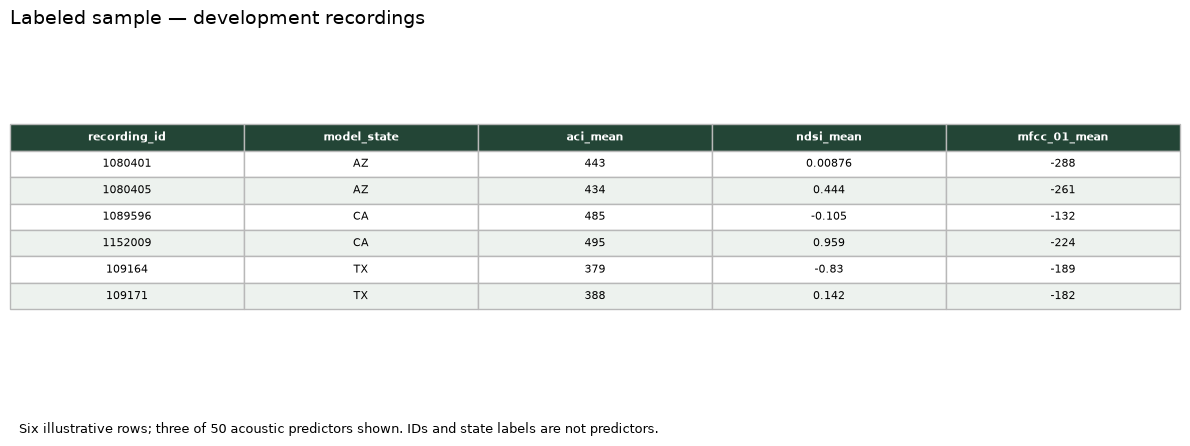

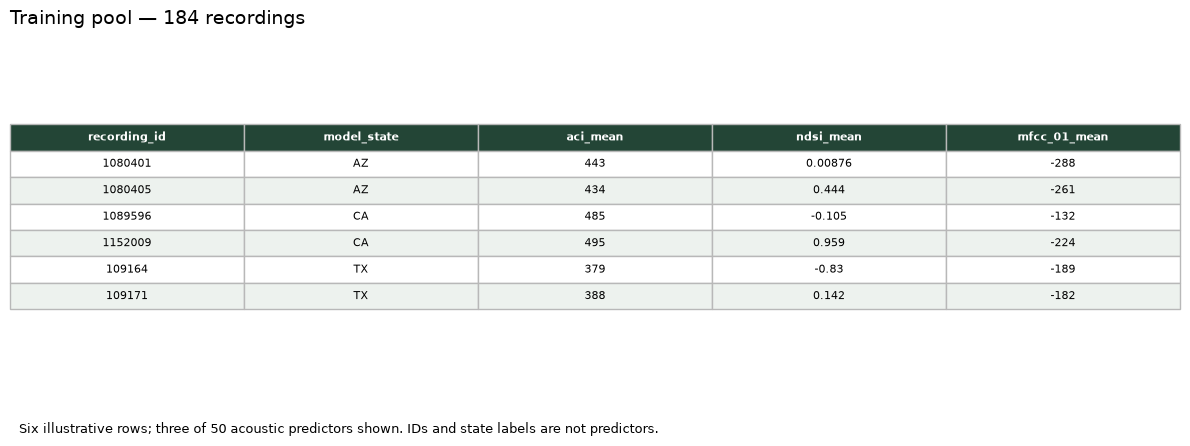

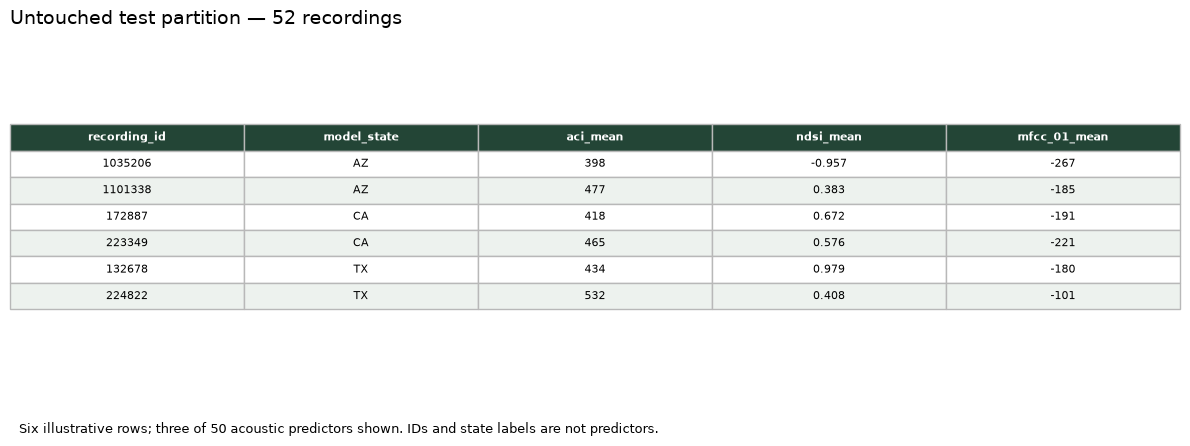

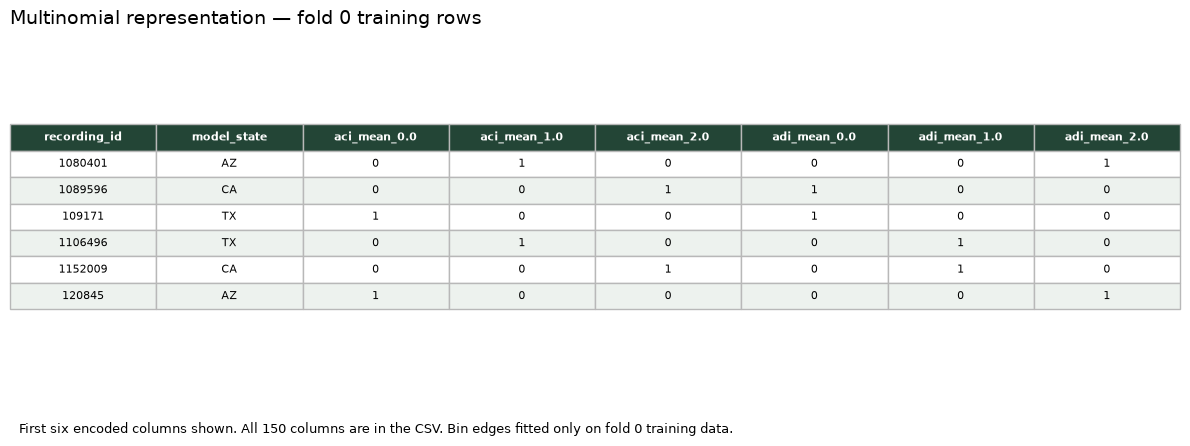

Reusable module: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\research\src\supervised\representations.py
Assignment artifacts: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\assignment_artifacts_20261101T073722281172Z
Classifiers fitted: 0


In [5]:
# Cell 5 — Reusable representations + assignment data exports/previews

import sys
import importlib
import matplotlib.pyplot as plt

# ---------- A. Save reusable preprocessing code ----------

module_dir = PROJECT_ROOT / "research/src/supervised"
module_dir.mkdir(parents=True, exist_ok=True)
module_path = module_dir / "representations.py"

module_source = '''"""Training-only acoustic representations. Fit inside CV folds."""
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer

def make_representations(mnb_bins=3):
    def imputer():
        return SimpleImputer(strategy="median", keep_empty_features=True)

    def bins(n, encoding):
        return KBinsDiscretizer(
            n_bins=n, encode=encoding, strategy="quantile",
            quantile_method="averaged_inverted_cdf", subsample=None,
        )

    return {
        "continuous": Pipeline([("impute", imputer())]),
        "multinomial_bins": Pipeline([
            ("impute", imputer()), ("encode", bins(mnb_bins, "onehot"))
        ]),
        "bernoulli_indicators": Pipeline([
            ("impute", imputer()), ("encode", bins(2, "ordinal"))
        ]),
    }
'''

if module_path.exists():
    assert module_path.read_text(encoding="utf-8") == module_source, (
        "Existing module differs. Stop rather than overwrite it."
    )
else:
    module_path.write_text(module_source, encoding="utf-8")

source_dir = str(PROJECT_ROOT / "research/src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

importlib.invalidate_caches()
from supervised.representations import make_representations

saved_templates = make_representations()
assert set(saved_templates) == set(representations)
for name in representations:
    assert (
        str(saved_templates[name].get_params())
        == str(representations[name].get_params())
    ), f"Saved configuration differs: {name}"

# ---------- B. Export labeled, untransformed data ----------

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
export_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / f"assignment_artifacts_{stamp}"
)
export_dir.mkdir(parents=True, exist_ok=False)
figure_dir = export_dir / "figures"
figure_dir.mkdir()

joined = split_table[[
    "recording_id", "model_state", "location_group", "partition"
]].merge(
    features[["recording_id", *feature_names]],
    on="recording_id",
    how="left",
    validate="one_to_one",
    sort=False,
)

assert len(joined) == 236
assert joined[feature_names].notna().all().all()

train_export = joined.loc[joined["partition"].eq("development")].copy()
test_export = joined.loc[joined["partition"].eq("test")].copy()

# Deterministic illustrative sample, drawn only from development.
sample_export = (
    train_export.sort_values(["model_state", "recording_id"])
    .groupby("model_state", group_keys=False).head(3)
)

train_export.to_csv(export_dir / "development_train.csv", index=False)
test_export.to_csv(export_dir / "heldout_test.csv", index=False)
sample_export.to_csv(export_dir / "labeled_sample.csv", index=False)

development.to_csv(export_dir / "development_folds.csv", index=False)
representation_checks.to_csv(
    export_dir / "representation_checks.csv", index=False
)

# Training-only encoded demonstration from validation fold 0.
encoded_names = demo_transformer.get_feature_names_out(feature_names)
encoded_values = (
    demo_training_encoded.toarray()
    if sparse.issparse(demo_training_encoded)
    else np.asarray(demo_training_encoded)
)
encoded_export = pd.DataFrame(encoded_values, columns=encoded_names)
encoded_export.insert(
    0, "model_state",
    development.set_index("recording_id")
    .loc[demo_training_ids, "model_state"].to_numpy(),
)
encoded_export.insert(0, "recording_id", demo_training_ids)
encoded_export.to_csv(
    export_dir / "fold0_training_encoded.csv", index=False
)

# ---------- C. Readable table figures ----------

def table_figure(frame, title, caption, filename):
    shown = frame.copy()
    for column in shown.select_dtypes(include="number"):
        shown[column] = shown[column].map(lambda x: f"{x:.3g}")

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=14, pad=15)

    table = ax.table(
        cellText=shown.astype(str).values,
        colLabels=shown.columns,
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.6)

    for (row, column), cell in table.get_celld().items():
        cell.set_edgecolor("#b8b8b8")
        if row == 0:
            cell.set_facecolor("#234536")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#ffffff" if row % 2 else "#edf2ee")

    fig.text(0.02, 0.025, caption, fontsize=9)
    fig.tight_layout(rect=[0, 0.09, 1, 1])
    fig.savefig(figure_dir / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

preview_columns = [
    "recording_id", "model_state", "aci_mean", "ndsi_mean", "mfcc_01_mean"
]

for frame, title, filename in [
    (sample_export, "Labeled sample — development recordings", "sample.png"),
    (train_export, "Training pool — 184 recordings", "training.png"),
    (test_export, "Untouched test partition — 52 recordings", "test.png"),
]:
    preview = (
        frame.sort_values(["model_state", "recording_id"])
        .groupby("model_state", group_keys=False).head(2)
    )
    table_figure(
        preview[preview_columns], title,
        "Six illustrative rows; three of 50 acoustic predictors shown. "
        "IDs and state labels are not predictors.",
        filename,
    )

table_figure(
    encoded_export.iloc[:6, :8],
    "Multinomial representation — fold 0 training rows",
    "First six encoded columns shown. All 150 columns are in the CSV. "
    "Bin edges fitted only on fold 0 training data.",
    "encoded_training.png",
)

# Preserve the artifact contract for the next notebook.
(export_dir / "artifact_manifest.json").write_text(
    json.dumps({
        "target": "model_state",
        "feature_allowlist": feature_names,
        "metadata_not_predictors": [
            "recording_id", "location_group", "partition"
        ],
        "primary_split": str(
            (split_dir / "primary_split_manifest.csv").relative_to(PROJECT_ROOT)
        ),
        "development_folds": str(
            (cv_dir / "development_fold_manifest.csv").relative_to(PROJECT_ROOT)
        ),
        "representation_module_sha256": sha256_file(module_path),
        "training_n": len(train_export),
        "test_n": len(test_export),
        "encoded_demo_scope": "Fold 0 training only; not a global transform",
    }, indent=2),
    encoding="utf-8",
)

print("Reusable module:", module_path)
print("Assignment artifacts:", export_dir)
print("Classifiers fitted: 0")